# T30. Validación temporal de las redes congeladas

**Objetivo.** Evaluar en la semana reservada las redes elegidas con los viajes del 1 al 21 de febrero. Comparar volumen, cobertura OD y P90 a toda Roma por geometría y repetir la prueba de T29 a pie en los dos núcleos. Los intervalos, radios y reglas son los mismos del ajuste. El conjunto de estaciones se conserva por huella.

In [1]:
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display

from comun.config import cargar_config
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.web import exportar
from peatones import ENLACE_MAX_M, META, evaluar, finalistas
from redes import (METODOS, OBJETIVO_PCT, RADIOS_PRINCIPALES, TABLAS, cobertura_split,
                   distancias, extremos, guardar, indicadores, leer)

info_t29 = json.loads((TABLAS / "T29_rutas_ajuste.json").read_text(encoding="utf-8"))
for nombre, huella in info_t29["seleccion"].items():
    if hashlib.sha256((TABLAS / nombre).read_bytes()).hexdigest() != huella:
        raise ValueError("La red de T28 cambió. Ejecuta T29 con la selección vigente.")

redes, estaciones = finalistas()
redes["prioridad"] = redes["rol"].map({"recomendada": 0, "menos_estaciones": 1, "radio_menor": 2})
redes = redes.sort_values("prioridad").drop(columns="prioridad")
cfg = cargar_config()
periodos_cfg = cfg["datos"]["periodos"]
franjas = cfg["exploracion"]["franjas_horarias"]
horas = {h: f for f, (inicio, fin) in franjas.items() for h in range(inicio, fin)}
assert set(horas) == set(range(24)) and sum(fin - inicio for inicio, fin in franjas.values()) == 24
tipos = ("laborable", "fin_de_semana")
estratos = pd.MultiIndex.from_product([tipos, franjas], names=["tipo_dia", "franja"])
geometria, diario, temporal, periodos = [], [], [], {}
for periodo, (inicio, fin) in periodos_cfg.items():
    viajes = cargar_viajes(periodo=periodo)
    n = len(viajes)
    dias = pd.date_range(inicio, fin, freq="D")
    periodos[periodo] = {"inicio": inicio, "fin": fin, "dias": len(dias), "viajes": n, "viajes_dia": n / len(dias)}
    salida = viajes["tsO"].dt.tz_convert(cfg["datos"]["zona_horaria"])
    desglose = pd.DataFrame({"fecha": salida.dt.strftime("%Y-%m-%d"), "franja": salida.dt.hour.map(horas),
                             "tipo_dia": np.where(salida.dt.dayofweek < 5, tipos[0], tipos[1])})
    for r in redes.itertuples():
        coords = estaciones.loc[estaciones["network_id"].eq(r.network_id), ["lon", "lat"]]
        d = distancias(extremos(viajes), coords).min(axis=1)
        m = indicadores(d, r.radio_m)
        geometria.append({"network_id": r.network_id, "periodo": periodo, "dias": len(dias),
                          "viajes_dia": n / len(dias), **m})
        _, _, ambos = cobertura_split(d, r.radio_m)
        datos = desglose.assign(cubiertos=ambos)
        for claves, indice, coleccion in (("fecha", dias.strftime("%Y-%m-%d").rename("fecha"), diario),
                                         (list(estratos.names), estratos, temporal)):
            serie = datos.groupby(claves)["cubiertos"].agg(viajes="size", viajes_cubiertos="sum")
            serie = serie.reindex(indice, fill_value=0).reset_index()
            assert serie["viajes"].sum() == n and serie["viajes_cubiertos"].sum() == m["viajes_cubiertos"]
            coleccion.append(serie.assign(periodo=periodo, network_id=r.network_id))

geo = pd.DataFrame(geometria)
ajuste_geo = geo.loc[geo["periodo"].eq("ajuste")].set_index("network_id")["viajes_cubiertos"]
assert (redes.set_index("network_id")["viajes_cubiertos"] == ajuste_geo.reindex(redes["network_id"])).all()
guardada = pd.concat(diario, ignore_index=True)
guardar(geo, "T30_validacion_geometrica")
guardar(guardada, "T30_cobertura_diaria")
franjas_medidas = pd.concat(temporal, ignore_index=True)
guardar(franjas_medidas, "T30_cobertura_franjas")

# Se descompone el cambio de la tasa ponderada por volumen en mezcla y cobertura por estrato.
claves = ["network_id", "tipo_dia", "franja"]
a, b = (franjas_medidas.loc[franjas_medidas["periodo"].eq(p)].set_index(claves) for p in ("ajuste", "reservada"))
b = b.reindex(a.index)
wa, wb = a["viajes"] / periodos["ajuste"]["viajes"], b["viajes"] / periodos["reservada"]["viajes"]
ca, cb = a["viajes_cubiertos"].div(a["viajes"].replace(0, np.nan)), b["viajes_cubiertos"].div(b["viajes"].replace(0, np.nan))
# Con un estrato vacío, su tasa contrafactual es la del periodo con observaciones.
ca, cb = ca.fillna(cb).fillna(0), cb.fillna(ca).fillna(0)
efectos = pd.DataFrame({
    "mezcla_pp": 100 * (wb - wa) * (ca + cb) / 2,
    "dentro_pp": 100 * (wa + wb) * (cb - ca) / 2,
}).reset_index()
cambio = geo.pivot(index="network_id", columns="periodo", values="pct_viajes_cubiertos")
suma = efectos.groupby("network_id")[["mezcla_pp", "dentro_pp"]].sum().sum(axis=1)
np.testing.assert_allclose(suma.reindex(cambio.index), cambio["reservada"] - cambio["ajuste"])
guardar(efectos, "T30_efectos_temporales")

muestra_reservada, control, ejemplos_reservados, curva_reservada = evaluar("reservada", redes, estaciones)
en_pie = pd.concat([leer("T29_cobertura_peatonal"), muestra_reservada], ignore_index=True)
guardar(en_pie, "T30_validacion_peatonal")
guardar(control, "T30_grafo_reservada")
radios_a_pie = pd.concat([leer("T29_sensibilidad_radio"), curva_reservada], ignore_index=True)
guardar(radios_a_pie, "T30_sensibilidad_peatonal")
grafos = pd.concat([leer("T29_grafo"), control], ignore_index=True)
display(efectos.groupby("network_id")[["mezcla_pp", "dentro_pp"]].sum().round(2))
display(geo[["network_id", "periodo", "viajes", "viajes_cubiertos", "pct_viajes_cubiertos", "d_p90_m"]].round(2))
display(muestra_reservada[["network_id", "sector", "viajes_comparables", "viajes_sin_par_rutas",
                          "pct_linea", "pct_a_pie", "delta_pp"]].round(2))

C:\Users\Javier\AppData\Local\Temp\ipykernel_26120\441366358.py:38: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  "tipo_dia": np.where(salida.dt.dayofweek < 5, tipos[0], tipos[1])})
C:\Users\Javier\AppData\Local\Temp\ipykernel_26120\441366358.py:38: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  "tipo_dia": np.where(salida.dt.dayofweek < 5, tipos[0], tipos[1])})


,mezcla_pp,dentro_pp
network_id,,
lscp_r250_k225,-0.02,-5.13
lscp_r300_k159,-0.03,-4.38
mclp_r300_k158,-0.03,-4.21


,network_id,periodo,viajes,viajes_cubiertos,pct_viajes_cubiertos,d_p90_m
0,lscp_r300_k159,ajuste,16756,13409,80.03,309.78
1,mclp_r300_k158,ajuste,16756,13370,79.79,310.43
2,lscp_r250_k225,ajuste,16756,13412,80.04,265.14
3,lscp_r300_k159,reservada,6614,5001,75.61,329.36
4,mclp_r300_k158,reservada,6614,4997,75.55,329.52
5,lscp_r250_k225,reservada,6614,4953,74.89,292.26


,network_id,sector,viajes_comparables,viajes_sin_par_rutas,pct_linea,pct_a_pie,delta_pp
0,lscp_r300_k159,tiber,249,2,87.15,54.62,-32.53
1,mclp_r300_k158,tiber,249,2,87.15,54.62,-32.53
2,lscp_r250_k225,tiber,249,2,89.96,47.39,-42.57
3,lscp_r300_k159,termini,182,0,75.82,30.22,-45.60
4,mclp_r300_k158,termini,182,0,75.82,30.22,-45.60
5,lscp_r250_k225,termini,182,0,71.43,43.96,-27.47
6,lscp_r300_k159,ambos,431,2,82.37,44.32,-38.05
7,mclp_r300_k158,ambos,431,2,82.37,44.32,-38.05
8,lscp_r250_k225,ambos,431,2,82.13,45.94,-36.19


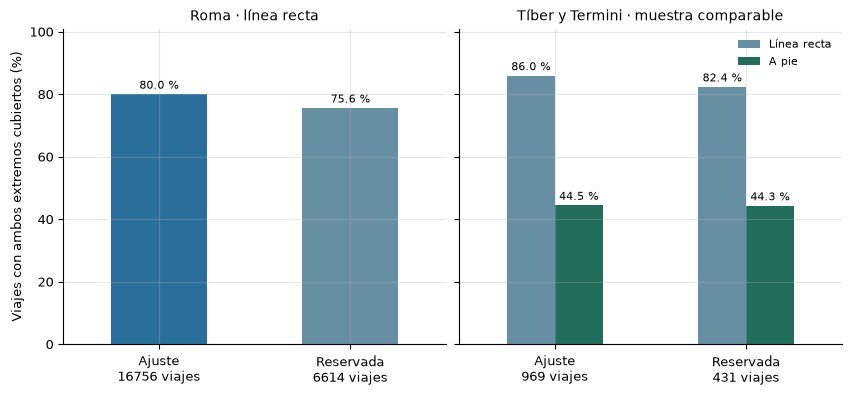

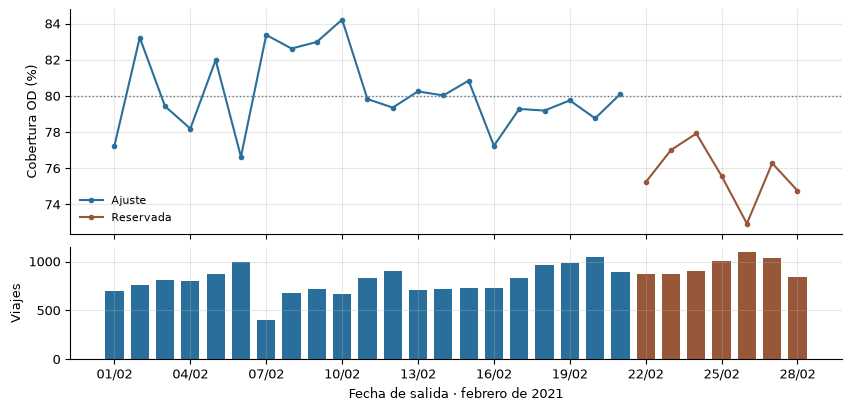

In [2]:
principal = redes.iloc[0]
principal_id = principal["network_id"]
r = geo.loc[geo["network_id"].eq(principal_id)].set_index("periodo").loc[["ajuste", "reservada"]]
p = en_pie.loc[en_pie["network_id"].eq(principal_id) & en_pie["sector"].eq("ambos")].set_index("periodo").loc[
    ["ajuste", "reservada"]
]
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.85), sharey=True, layout="constrained")
r["pct_viajes_cubiertos"].plot.bar(ax=axes[0], color=["#2a6f9b", "#678fa4"], rot=0)
axes[0].bar_label(axes[0].containers[0], fmt="%.1f %%", padding=2, fontsize=8)
axes[0].set_xticklabels([f"Ajuste\n{r.loc['ajuste','viajes']} viajes", f"Reservada\n{r.loc['reservada','viajes']} viajes"])
axes[0].set(ylabel="Viajes con ambos extremos cubiertos (%)", title="Roma · línea recta", ylim=(0, 101), xlabel="")
p[["pct_linea", "pct_a_pie"]].plot.bar(ax=axes[1], color=["#678fa4", "#226c5b"], rot=0)
for barra in axes[1].containers:
    axes[1].bar_label(barra, fmt="%.1f %%", padding=2, fontsize=8)
axes[1].set_xticklabels([f"Ajuste\n{p.loc['ajuste','viajes_comparables']} viajes", f"Reservada\n{p.loc['reservada','viajes_comparables']} viajes"])
axes[1].set(title="Tíber y Termini · muestra comparable", xlabel="")
axes[1].legend(["Línea recta", "A pie"], frameon=False)
guardar_figura(fig, "movilidad", "T30_validacion")

serie = guardada.loc[guardada["network_id"].eq(principal_id)].copy()
serie["cobertura"] = 100 * serie["viajes_cubiertos"] / serie["viajes"]
serie["fecha"] = pd.to_datetime(serie["fecha"])
fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(8.4, 4.0), sharex=True, layout="constrained",
                                   gridspec_kw={"height_ratios": [2, 1]})
for periodo, color, etiqueta in (("ajuste", "#2a6f9b", "Ajuste"), ("reservada", "#975738", "Reservada")):
    grupo = serie.loc[serie["periodo"].eq(periodo)]
    arriba.plot(grupo["fecha"], grupo["cobertura"], marker="o", markersize=3, color=color, label=etiqueta)
    abajo.bar(grupo["fecha"], grupo["viajes"], color=color, width=.72)
arriba.axhline(OBJETIVO_PCT, color="#657686", linestyle=":", linewidth=1)
arriba.set(ylabel="Cobertura OD (%)")
arriba.legend(frameon=False, loc="lower left")
abajo.set(ylabel="Viajes", xlabel="Fecha de salida · febrero de 2021", xticks=serie["fecha"].iloc[::3],
          xticklabels=serie["fecha"].dt.strftime("%d/%m").iloc[::3])
guardar_figura(fig, "movilidad", "T30_cobertura_diaria")

meta = json.loads(META.read_text(encoding="utf-8"))
sectores = [{"id": k, "nombre": v["nombre"], "nucleo": v["nucleo"],
             "recorte": v["recorte"], "fuentes": [{"url": f["fuente"], "fecha": f["snapshot"]} for f in v["ficheros"]]}
            for k, v in meta["sectores"].items()]
redes_web = redes[["network_id", "rol", "metodo", "radio_m", "k", "estaciones"]]
base = leer("T25_barrido")
base["network_id"] += "_r" + base["radio_m"].astype(str)
columnas_extremos = ["network_id", "viajes_un_extremo", "viajes_sin_cobertura", "d_origen_p90_m", "d_destino_p90_m"]
detalles = pd.concat([base[columnas_extremos], leer("T26_resultados")[columnas_extremos],
                      leer("T27_resultados")[columnas_extremos]], ignore_index=True)
comp = leer("T28_comparacion").merge(detalles, on="network_id", how="left", validate="one_to_one")
assert comp[columnas_extremos].notna().all().all()
cols_solver = ["network_id", "metodo", "k", "radio_m", "pct_viajes_cubiertos", "obj_factible",
               "estado_solver", "origen_solucion", "fuente_cota", "cota_obj", "brecha_pct", "solver_s", "optimalidad_probada"]
exportar("fase1", "t30_validacion_red", {
    "seleccionada": principal_id, "objetivo_pct": OBJETIVO_PCT, "radios_principales": RADIOS_PRINCIPALES,
    "huella_redes": info_t29["seleccion"]["T28_estaciones.csv"], "periodos": periodos, "metodos": METODOS,
    "redes": redes_web, "geometria": geo, "peatonal": en_pie, "sectores": sectores,
    "grafos": grafos, "enlace_max_m": ENLACE_MAX_M, "peatonal_radios": radios_a_pie,
    "diaria": guardada, "franjas": franjas_medidas, "efectos": efectos,
    "lscp_audit": leer("T26_certificados"), "mclp_audit": leer("T27_certificados"),
    "ejemplos": [*info_t29["ejemplos"], *ejemplos_reservados],
    "barrido": comp, "lscp": leer("T26_resultados")[cols_solver],
    "solver": leer("T27_resultados").loc[lambda t: t["metodo"].ne("voraz"), cols_solver],
})

**Lectura.** La comparación global usa todas las salidas elegibles de cada periodo. En la prueba a pie se compara sobre pares de rutas medibles en los dos sectores. La ficha web publica el denominador, los casos sin par de rutas y ejemplos de un tramo peatonal observado como extremo de viaje. Los resultados calculan acceso a una red propuesta, previo a la simulación de inventario.

**Desglose temporal.** Cada día publica viajes elegibles y cubiertos. Para comparar periodos se cruzan las franjas T12 con laborable o fin de semana, según la hora de salida de Roma. Por estrato, el cambio de peso se multiplica por la tasa media de ambos periodos y el cambio de tasa por el peso medio. Estos dos términos suman exactamente la diferencia global y se interpretan de forma descriptiva. Si un lado está vacío, se le asigna la tasa del periodo observado a efectos de la descomposición.

## Robustez: viajes encadenados y puntos de entrega del operador

**Qué queremos ver.** (a) La cobertura OD de la red principal si los viajes encadenados de T11 (el mismo patinete vuelve a salir a menos de 50 m y en menos de 5 min) se unieran en un solo viaje. (b) Qué parte de las entregas del operador (T11) cae a menos del radio de la red principal, frente a los orígenes de los viajes.

**Por qué importa.** (a) Si la cobertura dependiera de cómo se parte un trayecto, la red no sería robusta a esa decisión de limpieza. (b) Los puntos donde el operador ya deja los patinetes son los que él considera buenos para empezar viajes; una red que los dejara fuera obligaría a cambiar su operación.

In [3]:
from comun.encadenados import fusionar, pares_consecutivos
from comun.geo import haversine_m

SALTO_ENCADENADO_M, PAUSA_ENCADENADO_S = 50, 300   # los de T11, apartado 6
coords = estaciones.loc[estaciones["network_id"].eq(principal_id), ["lon", "lat"]]
radio = float(principal["radio_m"])
filas = []
for periodo in periodos_cfg:
    v = cargar_viajes(periodo=periodo)
    for version, w in (("tal cual", v), ("encadenados unidos", fusionar(v, SALTO_ENCADENADO_M, PAUSA_ENCADENADO_S))):
        m = indicadores(distancias(extremos(w), coords).min(axis=1), radio)
        filas.append({"periodo": periodo, "version": version, "viajes": m["viajes"],
                      "viajes_cubiertos": m["viajes_cubiertos"], "pct_viajes_cubiertos": m["pct_viajes_cubiertos"]})
robustez = pd.DataFrame(filas)
guardar(robustez, "T30_robustez_encadenados")

todos = cargar_viajes(solo_elegibles=False)
pares = pares_consecutivos(todos)
rec = pares[pares["salto_m"] > cfg["exploracion"]["umbral_recolocacion_m"]]
ajuste = cargar_viajes(periodo="ajuste")
puntos = {"entregas del operador": np.column_stack([rec["lonO_b"], rec["latO_b"]]),
          "recogidas del operador": np.column_stack([rec["lonD_a"], rec["latD_a"]]),
          "orígenes del ajuste": ajuste[["lonO", "latO"]].to_numpy()}
entregas = pd.DataFrame([{"puntos": nombre, "n": len(xy),
                          "pct_a_menos_del_radio": 100 * (distancias(xy, coords).min(axis=1) <= radio).mean()}
                         for nombre, xy in puntos.items()])
guardar(entregas, "T30_entregas_operador")
exportar("fase1", "t30_robustez", {"network_id": principal_id, "radio_m": radio,
                                   "encadenados": robustez, "entregas": entregas})
display(robustez.round(2), entregas.round(2))

,periodo,version,viajes,viajes_cubiertos,pct_viajes_cubiertos
0,ajuste,tal cual,16756,13409,80.03
1,ajuste,encadenados unidos,16005,12839,80.22
2,reservada,tal cual,6614,5001,75.61
3,reservada,encadenados unidos,6320,4795,75.87


,puntos,n,pct_a_menos_del_radio
0,entregas del operador,5111,90.28
1,recogidas del operador,5111,80.73
2,orígenes del ajuste,16756,89.88


**Lectura.** Al unir los viajes encadenados (pausa de 5 min como mucho y salto de 50 m como mucho) quedan 16 005 viajes en el ajuste y 6 320 en la reservada. La cobertura de la red principal pasa del 80,03 % al 80,22 % en el ajuste y del 75,61 % al 75,87 % en la reservada, así que mantenerlos separados no cambia la red. El 90,3 % de las entregas del operador queda a menos de 300 m de una estación, en línea con los orígenes del ajuste (89,9 %) y por encima de las recogidas (80,7 %). La red cubre los puntos de despliegue actuales.